In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [4]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
categorical = list(df.select_dtypes(exclude='number').columns)
numerical = list(df.select_dtypes(include='number').columns)
numerical.remove('converted')

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Question 1

In [13]:
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f'{col}: {auc:.3f}')

annual_income: 0.608
number_of_courses_viewed: 0.723
interaction_count: 0.765
lead_score: 0.788


## Question 2

In [16]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)
print(f'AUC: {auc:.3f}')

AUC: 0.732


## Question 3

In [18]:
threshold = np.linspace(0, 1, 101)

scores = []

for t in threshold:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predicted_positive = (y_pred >= t)
    predicted_negative = (y_pred < t)

    tp = np.sum(actual_positive & predicted_positive)
    fp = np.sum(actual_negative & predicted_positive)
    tn = np.sum(actual_negative & predicted_negative)
    fn = np.sum(actual_positive & predicted_negative)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    scores.append((t, tp, fp, tn, fn, precision, recall))

df_scores = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'tn', 'fn', 'precision', 'recall'])



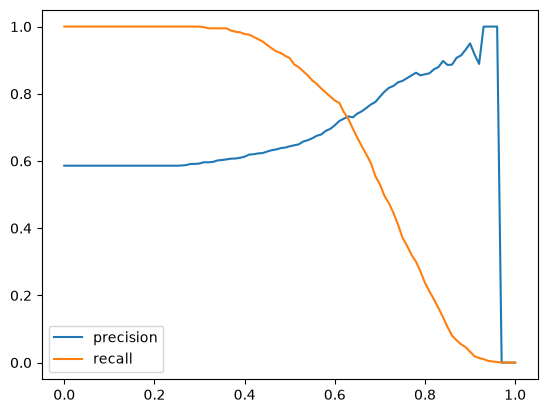

In [23]:
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.legend()
plt.show()

In [26]:
df_valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
df_valid['diff'] = (df_valid.precision - df_valid.recall).abs()

df_valid.sort_values('diff').head()

,threshold,tp,fp,tn,fn,precision,recall,diff
63,0.63,425,155,259,161,0.732759,0.725256,0.007503
62,0.62,437,165,249,149,0.725914,0.745734,0.019820
64,0.64,408,151,263,178,0.729875,0.696246,0.033629
61,0.61,453,177,237,133,0.719048,0.773038,0.053990
65,0.65,392,137,277,194,0.741021,0.668942,0.072079


## Question 4

In [28]:
df_scores['f1'] = 2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall)

df_scores.sort_values('f1', ascending=False).head()



,threshold,tp,fp,tn,fn,precision,recall,f1
41,0.41,572,352,62,14,0.619048,0.976109,0.757616
42,0.42,568,348,66,18,0.620087,0.969283,0.756325
43,0.43,564,342,72,22,0.622517,0.962457,0.756032
45,0.45,554,328,86,32,0.628118,0.945392,0.754768
44,0.44,560,338,76,26,0.623608,0.955631,0.754717


## Question 5


In [38]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred



In [41]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores2 = []

for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=1.0)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores2.append(auc)
        

print('%.3f +- %.3f' % (np.mean(scores2), np.std(scores2)))

0.732 +- 0.007


## Question 6

In [42]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores3 = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr.converted.values
        y_va = df_va.converted.values

        dv, model = train(df_tr, y_tr, C=C)
        y_pred_va = predict(df_va, dv, model)

        auc = roc_auc_score(y_va, y_pred_va)
        scores3.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores3), np.std(scores3)))

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
